In [8]:
!zip -r resunet_swinseg_basic_outputs.zip /content/resunet_swinseg_outputs

  adding: content/resunet_swinseg_outputs/ (stored 0%)
  adding: content/resunet_swinseg_outputs/training_loss.png (deflated 22%)
  adding: content/resunet_swinseg_outputs/test_metrics.png (deflated 22%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/ (stored 0%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/011_prediction.png (deflated 14%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/001_prediction.png (deflated 8%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/027_prediction.png (deflated 7%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/073_prediction.png (deflated 10%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/082_prediction.png (deflated 5%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/068_prediction.png (deflated 20%)
  adding: content/resunet_swinseg_outputs/test_predicted_masks/012_prediction.png (deflated 16%)
  adding: content/resunet_swinseg_outputs/te

In [1]:
!unzip -q /content/GLaS.zip -d /content/

In [2]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE = 2
PRED_THRESHOLD = 0.5
DATASET_ROOT = "/content/Warwick_QU_Dataset"  # Change this to the folder containing train, val, and test
OUTPUT_DIR = '/content/unet_GLaS_baseline_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.isdir(DATASET_ROOT):
    raise FileNotFoundError(f"Dataset root not found: {DATASET_ROOT}. Set DATASET_ROOT to the extracted folder containing train, val, and test.")


gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError("TensorFlow cannot detect a GPU. Check CUDA/TensorFlow compatibility and restart the kernel.")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print(f"Could not enable memory growth for {gpu}: {exc}")

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow:", tf.__version__)
print("Visible GPUs:", gpus)

TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
def get_pairs(image_dir, mask_dir):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    def collect_files(directory, is_mask=False):
        files = {}

        if not os.path.isdir(directory):
            raise FileNotFoundError(f"Directory not found: {directory}")

        for name in sorted(os.listdir(directory)):
            path = os.path.join(directory, name)

            if not os.path.isfile(path):
                continue

            stem, ext = os.path.splitext(name)

            if ext.lower() not in valid_extensions:
                continue

            # Remove the '_anno' suffix from mask filenames
            if is_mask and stem.lower().endswith("_anno"):
                stem = stem[:-5]

            key = stem.casefold()

            if key in files:
                raise ValueError(f"Duplicate filename after normalization: {name}")

            files[key] = path

        return files

    image_files = collect_files(image_dir)
    mask_files = collect_files(mask_dir, is_mask=True)

    missing_masks = sorted(set(image_files) - set(mask_files))
    orphan_masks = sorted(set(mask_files) - set(image_files))

    if missing_masks or orphan_masks:
        raise ValueError(
            f"Image/mask pairing is incomplete.\n"
            f"Images without masks: {missing_masks[:10]}\n"
            f"Masks without images: {orphan_masks[:10]}"
        )

    return [
        (image_files[key], mask_files[key])
        for key in sorted(image_files)
    ]


def _decode_path(path):
    if isinstance(path, np.ndarray):
        path = path.item()
    return os.fsdecode(path)


def load_image_mask(img_path, mask_path):
    img_path = _decode_path(img_path)
    mask_path = _decode_path(mask_path)
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMG_SIZE, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    threshold = 0 if mask.max(initial=0) <= 1 else 127
    mask = (mask > threshold).astype(np.float32)[..., np.newaxis]
    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    rotations = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    return tf.image.rot90(image, rotations), tf.image.rot90(mask, rotations)


def make_dataset(split_pairs, training=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")
    image_paths = [pair[0] for pair in split_pairs]
    mask_paths = [pair[1] for pair in split_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(split_pairs), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Use the dataset's existing train/val/test folders. No re-splitting is performed.
train_image_dir = '/content/Warwick_QU_Dataset/train/img'
train_mask_dir = '/content/Warwick_QU_Dataset/train/mask'
val_image_dir = '/content/Warwick_QU_Dataset/val/img'
val_mask_dir = '/content/Warwick_QU_Dataset/val/mask'
test_image_dir = '/content/Warwick_QU_Dataset/test/img'
test_mask_dir = '/content/Warwick_QU_Dataset/test/mask'

train_pairs = get_pairs(train_image_dir, train_mask_dir)
val_pairs = get_pairs(val_image_dir, val_mask_dir)
test_pairs = get_pairs(test_image_dir, test_mask_dir)

if not train_pairs or not val_pairs or not test_pairs:
    raise ValueError(
        "Each existing split must contain at least one correctly paired image and mask. "
        f"Found train={len(train_pairs)}, val={len(val_pairs)}, test={len(test_pairs)}."
    )

split_pairs = {
    "train": train_pairs,
    "validation": val_pairs,
    "test": test_pairs,
}
split_keys = {
    name: {os.path.abspath(image_path) for image_path, _ in split}
    for name, split in split_pairs.items()
}
if any(
    split_keys[a] & split_keys[b]
    for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))
):
    raise AssertionError("The provided dataset has overlapping image paths between splits.")

manifest_rows = [
    {
        "split": split_name,
        "image": image_path,
        "mask": mask_path,
        "image_filename": os.path.basename(image_path),
    }
    for split_name, split in split_pairs.items()
    for image_path, mask_path in sorted(split, key=lambda pair: pair[0])
]
manifest_path = os.path.join(OUTPUT_DIR, "dataset_split_manifest.csv")
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)

print("Using the dataset's existing splits; no samples were reallocated.")
for split_name, split in split_pairs.items():
    print(f"{split_name.title():12s}: {len(split):4d} images")
print(f"Saved split manifest: {manifest_path}")

Using the dataset's existing splits; no samples were reallocated.
Train       :  133 images
Validation  :   16 images
Test        :   16 images
Saved split manifest: /content/unet_GLaS_baseline_outputs/dataset_split_manifest.csv


Model: "UNet_Binary"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_1[

 Total params: 7,771,873 (29.65 MB)

 Trainable params: 7,765,985 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.5752 - dice_coef: 0.4781 - iou_coef: 0.3166 - loss: 0.5219
Epoch 1: val_dice_coef improved from None to 0.50248, saving model to /content/unet_GLaS_baseline_outputs/best_unet.keras

Epoch 1: finished saving model to /content/unet_GLaS_baseline_outputs/best_unet.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 85s 576ms/step - accuracy: 0.6255 - dice_coef: 0.5301 - iou_coef: 0.3653 - loss: 0.4707 - val_accuracy: 0.6240 - val_dice_coef: 0.5025 - val_iou_coef: 0.3377 - val_loss: 0.4975 - learning_rate: 1.0000e-04
Epoch 2/50
66/67 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.7002 - dice_coef: 0.6468 - iou_coef: 0.4840 - loss: 0.3532
Epoch 2: val_dice_coef improved from 0.50248 to 0.61127, saving model to /content/unet_GLaS_baseline_outputs/best_unet.keras

Epoch 2: finished saving model to /content/unet_GLaS_baseline_outputs/best_unet.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.7147 - dice_coef: 0.6647 - iou_coef: 0.5056 

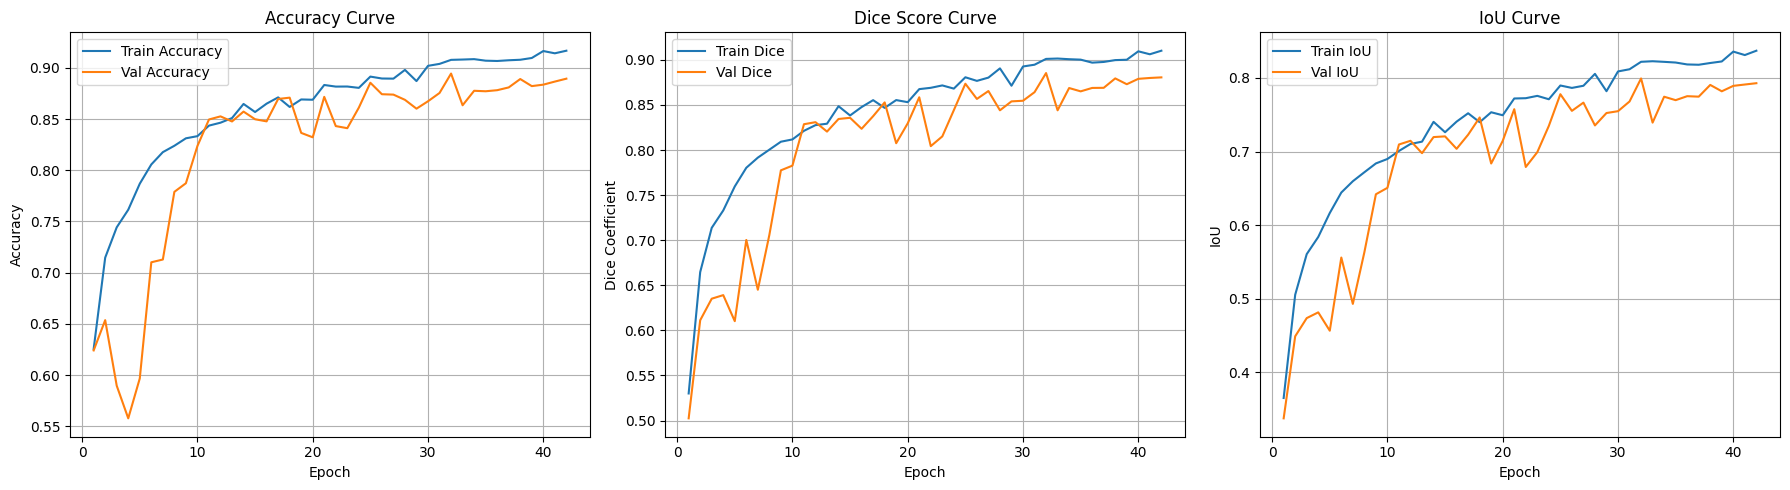

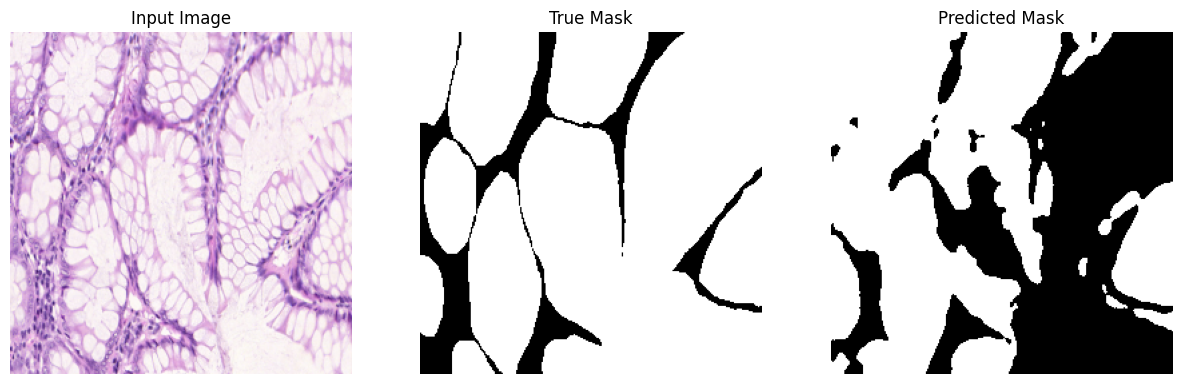

In [4]:
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def down_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPool2D((2, 2))(c)
    p = layers.Dropout(0.2)(p)
    return c, p

def up_block(x, skip, filters):
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([x, skip])
    x = layers.Dropout(0.2)(x)
    x = conv_block(x, filters)
    return x

def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    s1, p1 = down_block(inputs, 32)
    s2, p2 = down_block(p1, 64)
    s3, p3 = down_block(p2, 128)
    s4, p4 = down_block(p3, 256)

    bottleneck = conv_block(p4, 512)

    u1 = up_block(bottleneck, s4, 256)
    u2 = up_block(u1, s3, 128)
    u3 = up_block(u2, s2, 64)
    u4 = up_block(u3, s1, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u4)

    model = Model(inputs, outputs, name="UNet_Binary")
    return model

model = build_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=["accuracy", dice_coef, iou_coef]
)

model.summary()

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "best_unet.keras"),
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs_range, hist["val_accuracy"], label="Val Accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, hist["dice_coef"], label="Train Dice")
    plt.plot(epochs_range, hist["val_dice_coef"], label="Val Dice")
    plt.title("Dice Score Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Dice Coefficient")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, hist["iou_coef"], label="Train IoU")
    plt.plot(epochs_range, hist["val_iou_coef"], label="Val IoU")
    plt.title("IoU Curve")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_curves(history)

def show_prediction(model, pair):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

show_prediction(model, val_pairs[0])


Loaded best validation-selected checkpoint: /content/unet_GLaS_baseline_outputs/best_unet.keras
Prediction threshold: 0.5
Boundary tolerance: 2 pixels
Validation image 1/16: testA_1.png
Validation image 2/16: testA_10.png
Validation image 3/16: testA_11.png
Validation image 4/16: testA_12.png
Validation image 5/16: testA_13.png
Validation image 6/16: testA_14.png
Validation image 7/16: testA_15.png
Validation image 8/16: testA_16.png
Validation image 9/16: testA_2.png
Validation image 10/16: testA_3.png
Validation image 11/16: testA_4.png
Validation image 12/16: testA_5.png
Validation image 13/16: testA_6.png
Validation image 14/16: testA_7.png
Validation image 15/16: testA_8.png
Validation image 16/16: testA_9.png

VALIDATION METRICS — MACRO-AVERAGE OVER 16 IMAGES
IoU                     : 0.8021 ± 0.1195
Recall                  : 0.8950 ± 0.1243
Precision               : 0.8908 ± 0.0841
Dice Coefficient        : 0.8854 ± 0.0771
Boundary F1             : 0.7082 ± 0.1310
Boundary Recal

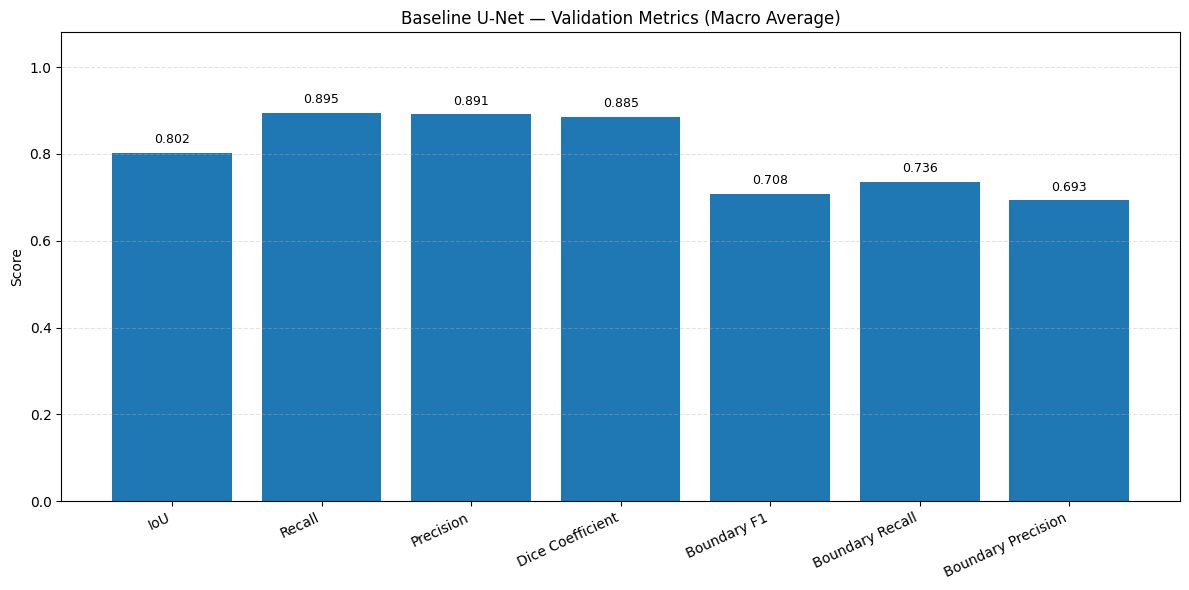

Saved macro-average plot: /content/unet_GLaS_baseline_outputs/validation_metrics_macro_average.png


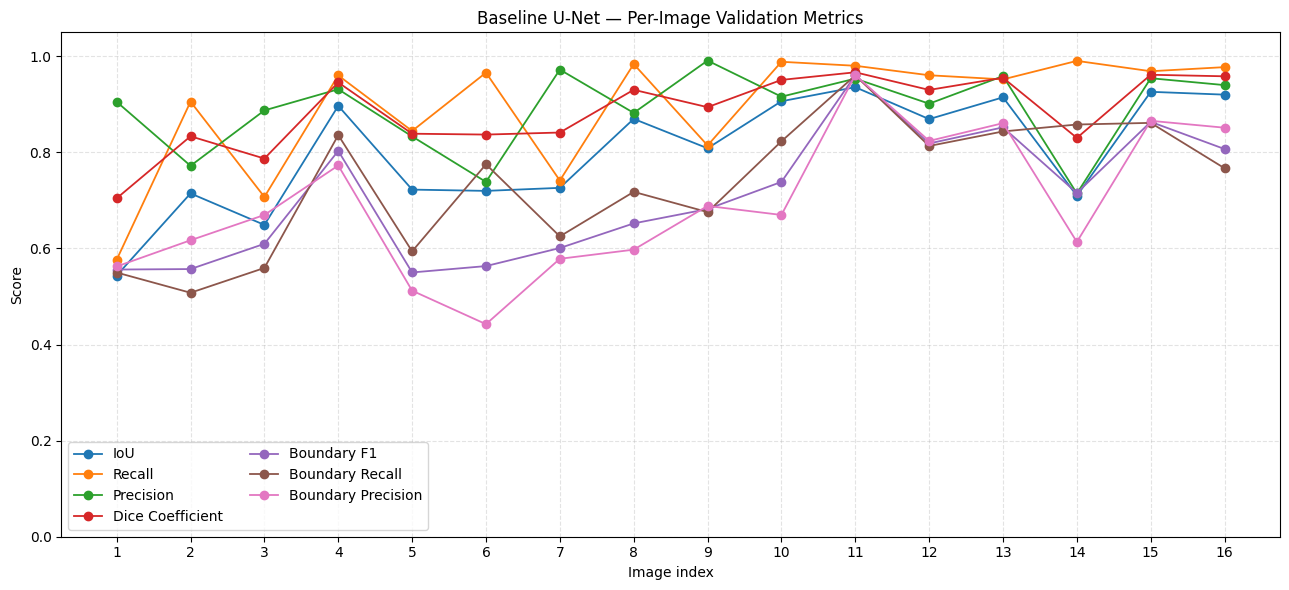

Saved per-image plot: /content/unet_GLaS_baseline_outputs/validation_metrics_per_image.png
Test image 1/16: testB_1.png
Test image 2/16: testB_10.png
Test image 3/16: testB_11.png
Test image 4/16: testB_12.png
Test image 5/16: testB_13.png
Test image 6/16: testB_14.png
Test image 7/16: testB_15.png
Test image 8/16: testB_16.png
Test image 9/16: testB_2.png
Test image 10/16: testB_3.png
Test image 11/16: testB_4.png
Test image 12/16: testB_5.png
Test image 13/16: testB_6.png
Test image 14/16: testB_7.png
Test image 15/16: testB_8.png
Test image 16/16: testB_9.png

TEST METRICS — MACRO-AVERAGE OVER 16 IMAGES
IoU                     : 0.8049 ± 0.1253
Recall                  : 0.9026 ± 0.1197
Precision               : 0.8850 ± 0.0874
Dice Coefficient        : 0.8865 ± 0.0825
Boundary F1             : 0.6857 ± 0.1510
Boundary Recall         : 0.7246 ± 0.1672
Boundary Precision      : 0.6560 ± 0.1485
Saved per-image metrics: /content/unet_GLaS_baseline_outputs/test_metrics_per_image.csv
Save

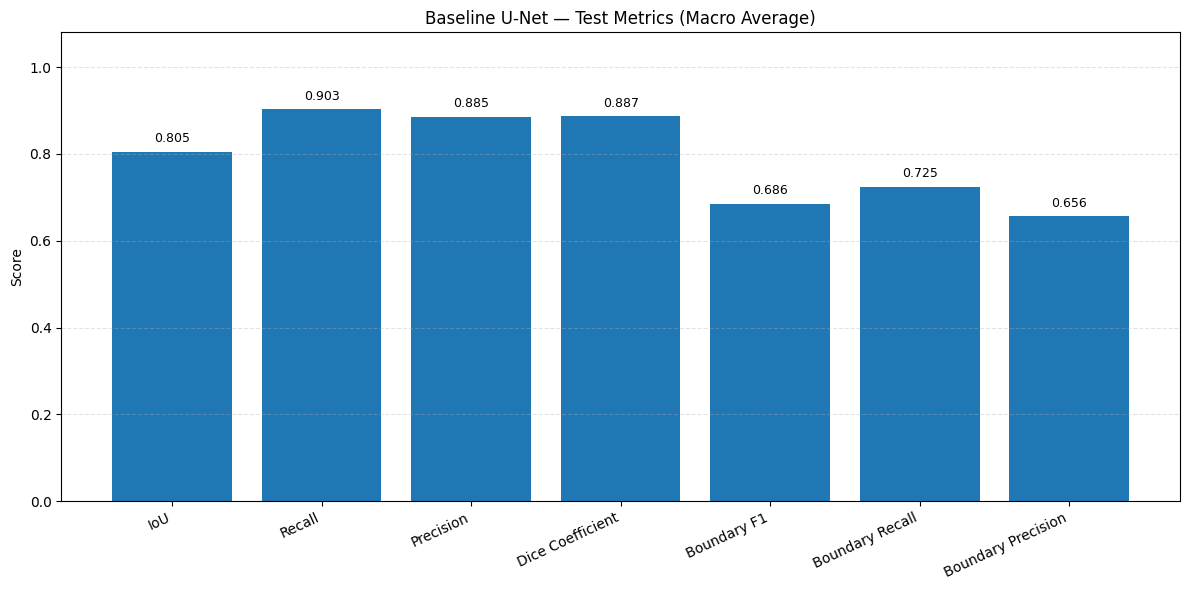

Saved macro-average plot: /content/unet_GLaS_baseline_outputs/test_metrics_macro_average.png


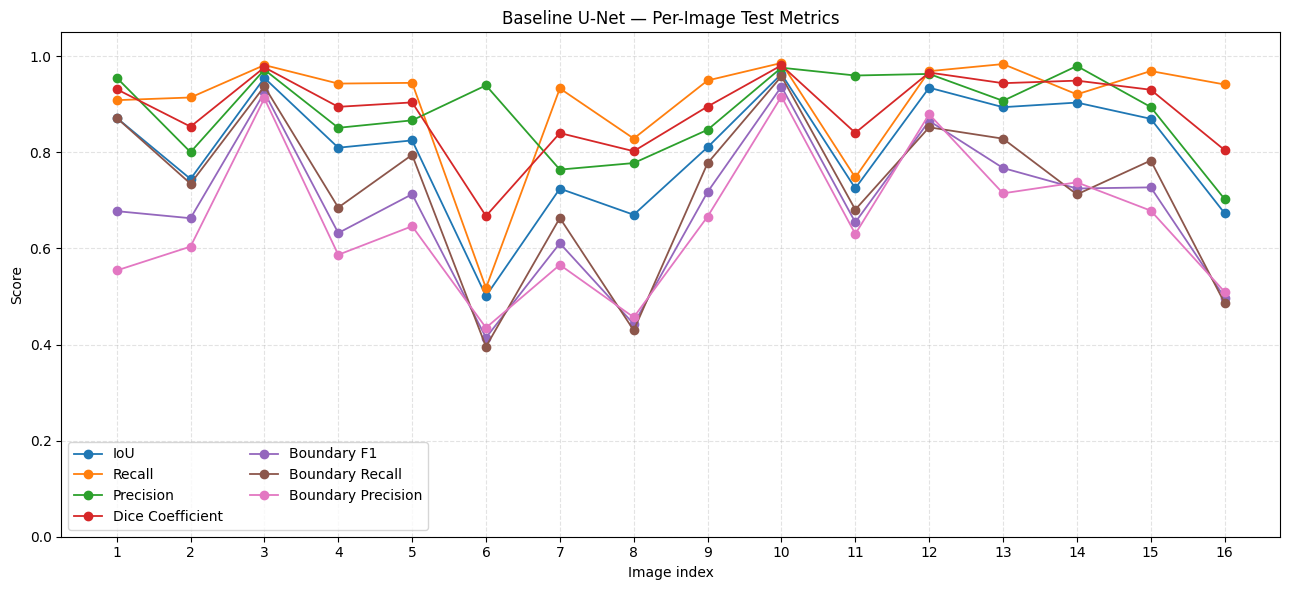

Saved per-image plot: /content/unet_GLaS_baseline_outputs/test_metrics_per_image.png

TEST EVALUATION COMPLETE. Report the TEST summary as final held-out performance;
keep the validation summary separate, and do not describe old validation scores as test results.


In [5]:
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "best_unet.keras")
if not os.path.isfile(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_MODEL_PATH}. Run the notebook from the start "
        "so training creates the checkpoint before evaluation."
    )

_custom_objects = {name: globals()[name] for name in ("FixedKernelLayer", "LearnableDepthwiseConv2D") if name in globals()}
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH, custom_objects=_custom_objects, compile=False
)
print("Loaded best validation-selected checkpoint:", BEST_MODEL_PATH)
print("Prediction threshold:", PRED_THRESHOLD)
print("Boundary tolerance:", BOUNDARY_TOLERANCE, "pixels")

METRIC_NAMES = [
    "iou", "recall", "precision", "dice_coef",
    "boundary_f1", "boundary_recall", "boundary_precision",
]
DISPLAY_NAMES = {
    "iou": "IoU",
    "recall": "Recall",
    "precision": "Precision",
    "dice_coef": "Dice Coefficient",
    "boundary_f1": "Boundary F1",
    "boundary_recall": "Boundary Recall",
    "boundary_precision": "Boundary Precision",
}

def _extract_boundary(mask):
    mask = (np.asarray(mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(
        mask,
        np.ones((3, 3), dtype=np.uint8),
        iterations=1,
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    return (mask - eroded).astype(np.uint8)

def _segmentation_metrics(gt_mask, pred_mask, tolerance=2):
    gt = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Mask shape mismatch: GT={gt.shape}, prediction={pred.shape}")

    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) else (1.0 if (tp + fn) == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) else (1.0 if (tp + fp) == 0 else 0.0)
    dice_den = 2 * tp + fp + fn
    dice = (2 * tp / dice_den) if dice_den else 1.0
    iou_den = tp + fp + fn
    iou = tp / iou_den if iou_den else 1.0

    gt_boundary = _extract_boundary(gt)
    pred_boundary = _extract_boundary(pred)
    gt_count, pred_count = int(gt_boundary.sum()), int(pred_boundary.sum())
    tolerance = max(0, int(tolerance))
    if tolerance:
        kernel_size = 2 * tolerance + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
        gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
        pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)
    else:
        gt_dilated, pred_dilated = gt_boundary, pred_boundary

    matched_pred = int(np.sum((pred_boundary > 0) & (gt_dilated > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (pred_dilated > 0)))
    boundary_precision = (
        matched_pred / pred_count if pred_count else (1.0 if gt_count == 0 else 0.0)
    )
    boundary_recall = (
        matched_gt / gt_count if gt_count else (1.0 if pred_count == 0 else 0.0)
    )
    boundary_sum = boundary_precision + boundary_recall
    boundary_f1 = 2 * boundary_precision * boundary_recall / boundary_sum if boundary_sum else 0.0

    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }

def evaluate_split(split_pairs, split_name, save_prediction_masks=False):
    if not split_pairs:
        raise ValueError(f"The {split_name} split is empty.")
    rows = []
    prediction_dir = os.path.join(OUTPUT_DIR, "test_predictions")
    if save_prediction_masks:
        os.makedirs(prediction_dir, exist_ok=True)

    for idx, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(os.fsencode(image_path), os.fsencode(mask_path))
        pred_prob = best_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
        pred_mask = (np.asarray(pred_prob).squeeze() >= PRED_THRESHOLD).astype(np.uint8)
        gt_binary = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
        scores = _segmentation_metrics(gt_binary, pred_mask, BOUNDARY_TOLERANCE)
        rows.append({"image": os.path.basename(image_path), **scores})

        if save_prediction_masks:
            out_name = os.path.splitext(os.path.basename(image_path))[0] + "_pred.png"
            cv2.imwrite(os.path.join(prediction_dir, out_name), pred_mask * 255)
        print(f"{split_name.title()} image {idx}/{len(split_pairs)}: {os.path.basename(image_path)}")

    results_df = pd.DataFrame(rows)
    means = results_df[METRIC_NAMES].mean()
    stds = results_df[METRIC_NAMES].std(ddof=1).fillna(0.0) if len(results_df) > 1 else means * 0.0

    print("\n" + "=" * 68)
    print(f"{split_name.upper()} METRICS — MACRO-AVERAGE OVER {len(results_df)} IMAGES")
    print("=" * 68)
    for metric in METRIC_NAMES:
        print(f"{DISPLAY_NAMES[metric]:<24}: {means[metric]:.4f} ± {stds[metric]:.4f}")
    print("=" * 68)

    summary_df = pd.DataFrame({
        "metric": [DISPLAY_NAMES[m] for m in METRIC_NAMES],
        "mean_score": [float(means[m]) for m in METRIC_NAMES],
        "std_score": [float(stds[m]) for m in METRIC_NAMES],
        "n_images": [len(results_df)] * len(METRIC_NAMES),
    })
    per_image_csv = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.csv")
    summary_csv = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_summary.csv")
    results_df.to_csv(per_image_csv, index=False)
    summary_df.to_csv(summary_csv, index=False)
    print("Saved per-image metrics:", per_image_csv)
    print("Saved summary metrics :", summary_csv)

    values = [float(means[m]) for m in METRIC_NAMES]
    labels = [DISPLAY_NAMES[m] for m in METRIC_NAMES]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(labels, values)
    plt.ylim(0, 1.08)
    plt.ylabel("Score")
    plt.title(f"Baseline U-Net — {split_name.title()} Metrics (Macro Average)")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    macro_plot = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_macro_average.png")
    plt.savefig(macro_plot, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved macro-average plot:", macro_plot)

    image_numbers = np.arange(1, len(results_df) + 1)
    plt.figure(figsize=(13, 6))
    for metric in METRIC_NAMES:
        plt.plot(image_numbers, results_df[metric], marker="o", linewidth=1.3,
                 label=DISPLAY_NAMES[metric])
    plt.ylim(0, 1.05)
    plt.xlabel("Image index")
    plt.ylabel("Score")
    plt.title(f"Baseline U-Net — Per-Image {split_name.title()} Metrics")
    plt.xticks(image_numbers)
    plt.grid(True, linestyle="--", alpha=0.35)
    plt.legend(ncol=2)
    plt.tight_layout()
    per_image_plot = os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.png")
    plt.savefig(per_image_plot, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved per-image plot:", per_image_plot)
    return results_df, summary_df

if "load_image_mask" not in globals():
    raise RuntimeError("load_image_mask() is not defined. Run the data-loading cells first.")
if "val_pairs" not in globals() or "test_pairs" not in globals():
    raise RuntimeError("val_pairs/test_pairs not found. Run the split cell and retrain first.")

validation_results, validation_summary = evaluate_split(
    val_pairs, "validation", save_prediction_masks=False
)

test_results, test_summary = evaluate_split(
    test_pairs, "test", save_prediction_masks=True
)
print("\nTEST EVALUATION COMPLETE. Report the TEST summary as final held-out performance;")
print("keep the validation summary separate, and do not describe old validation scores as test results.")
